<a href="https://colab.research.google.com/github/xoxoreyniel/APM1220/blob/main/FA3_Awit_and_Deloyola.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **Scenario: Student Academic Performance**

Our simulation focuses on student academic
performance. We use three variables to represent factors that may be related to a student's performance: Study Hours, Sleep Hours, and Exam Score.

## Part A. Define Your Multivariate Normal Distribution

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

np.random.seed(123)

# Mean vector: [Studyhours, Sleephours, Examscore]
mu = np.array([15, 7, 75])

# Covariance matrix, built from sd1=5, sd2=1.2, sd3=10 and
# correlations rho12=-0.30, rho13=0.55, rho23=0.35
Sigma = np.array([
    [25.00, -1.80, 27.50],
    [-1.80,  1.44,  4.20],
    [27.50,  4.20, 100.00]
])

labels = ["Studyhours", "Sleephours", "Examscore"]
Sigma_df = pd.DataFrame(Sigma, index=labels, columns=labels)
print("Sigma:")
print(Sigma_df.round(2))

# A valid covariance matrix must be symmetric and positive definite
print("\nSymmetric:", np.allclose(Sigma, Sigma.T))
eigvals = np.linalg.eigvalsh(Sigma)
print("Eigenvalues:", np.round(eigvals, 3))
print("Positive definite:", np.all(eigvals > 0))

# Convert covariance to correlation for reporting
D_inv = np.diag(1 / np.sqrt(np.diag(Sigma)))
R = D_inv @ Sigma @ D_inv
R_df = pd.DataFrame(R, index=labels, columns=labels)
print("\nCorrelation matrix R:")
print(R_df.round(3))

Sigma:
            Studyhours  Sleephours  Examscore
Studyhours        25.0       -1.80       27.5
Sleephours        -1.8        1.44        4.2
Examscore         27.5        4.20      100.0

Symmetric: True
Eigenvalues: [  0.735  16.593 109.112]
Positive definite: True

Correlation matrix R:
            Studyhours  Sleephours  Examscore
Studyhours        1.00       -0.30       0.55
Sleephours       -0.30        1.00       0.35
Examscore         0.55        0.35       1.00


In Part A , We defined a multivariate normal distribution for our student academic performance scenario, using Study Hours, Sleep Hours, and Exam Score as the three variables. We specified the mean vector to represent the expected average values of these variables and created a covariance matrix to describe their variability and relationships.

The correlation matrix shows how the variables are related to one another. In our scenario, Study Hours and Exam Score have a positive relationship, suggesting that students who spend more time studying tend to have higher exam scores. Study Hours and Sleep Hours have a negative relationship, while Sleep Hours and Exam Score have a positive relationship.

We also checked whether the covariance matrix was symmetric and positive definite. This confirms that the matrix is valid for our multivariate normal simulation.

## Part B. Generate and Explore the Simulated Data

   Studyhours  Sleephours  Examscore
0    5.201044    9.193566  75.628679
1   16.583841    5.510123  72.363444
2    9.607088    7.821726  72.053691
3   14.711713    5.503144  55.038676
4   18.133768    7.272951  75.068683
Sample mean:
 Studyhours    15.093
Sleephours     6.989
Examscore     74.786
dtype: float64 

Sample covariance:
             Studyhours  Sleephours  Examscore
Studyhours      27.135      -2.019     28.978
Sleephours      -2.019       1.485      3.689
Examscore       28.978       3.689     97.335 

Sample correlation:
             Studyhours  Sleephours  Examscore
Studyhours       1.000      -0.318      0.564
Sleephours      -0.318       1.000      0.307
Examscore        0.564       0.307      1.000
            theoretical  simulated
Studyhours           15     15.093
Sleephours            7      6.989
Examscore            75     74.786

             theoretical  simulated
Studyhours        25.00     27.135
Sleephours         1.44      1.485
Examscore        100.00   

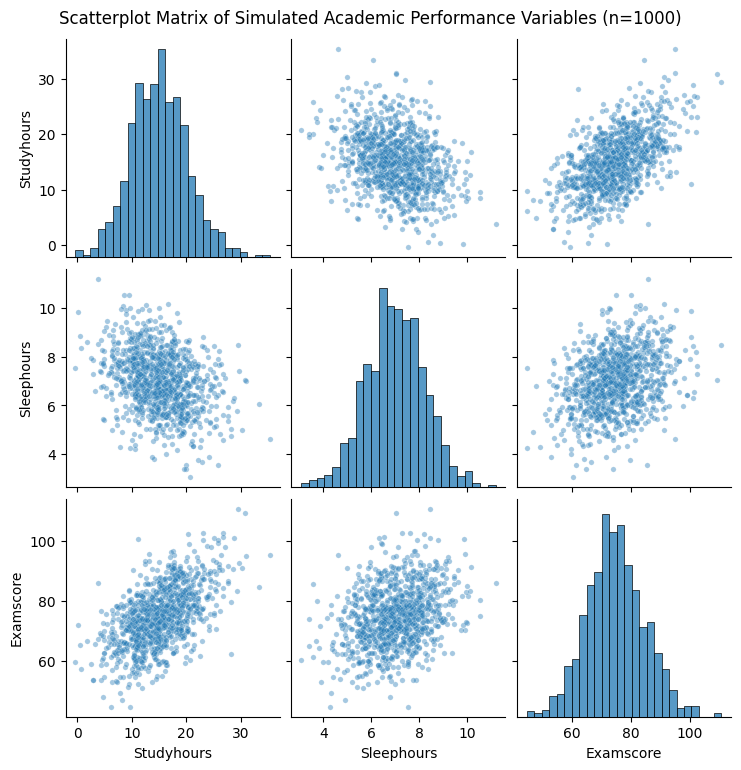

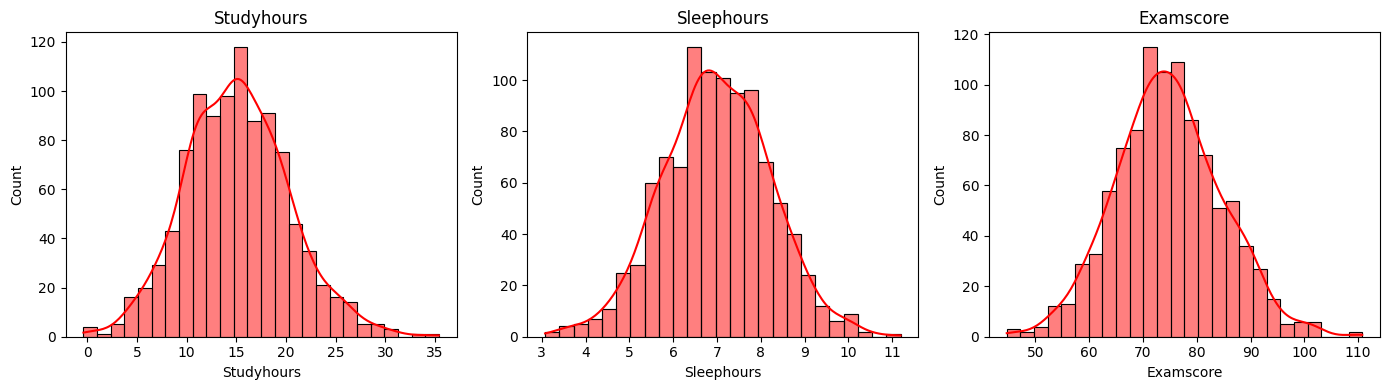

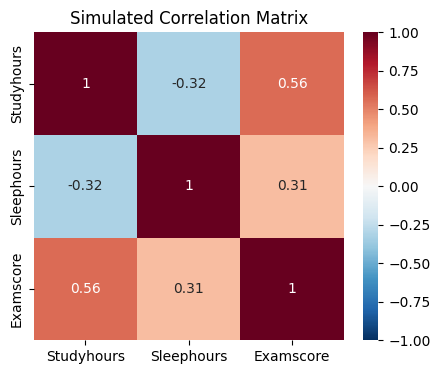

In [ ]:
n = 1000
X = np.random.multivariate_normal(mu, Sigma, size=n)
df = pd.DataFrame(X, columns=labels)
print(df.head())

# Descriptive statistics
sample_mean = df.mean()
sample_cov  = df.cov()
sample_corr = df.corr()

print("Sample mean:\n", sample_mean.round(3), "\n")
print("Sample covariance:\n", sample_cov.round(3), "\n")
print("Sample correlation:\n", sample_corr.round(3))

# Side-by-side comparison with theoretical values
compare_mean = pd.DataFrame({
    "theoretical": mu,
    "simulated": sample_mean.values
}, index=labels)
print(compare_mean.round(3))

compare_var = pd.DataFrame({
    "theoretical": np.diag(Sigma),
    "simulated": np.diag(sample_cov.values)
}, index=labels)
print("\n", compare_var.round(3))

# Scatterplot matrix
sns.pairplot(df, diag_kind="hist", plot_kws={"alpha": 0.4, "s": 15})
plt.suptitle("Scatterplot Matrix of Simulated Academic Performance Variables (n=1000)", y=1.02)
plt.show()

# Histograms / density plots
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, labels):
    sns.histplot(df[col], kde=True, ax=ax, color="red")
    ax.set_title(col)
plt.tight_layout()
plt.show()

# Correlation heatmap
plt.figure(figsize=(5, 4))
sns.heatmap(sample_corr, annot=True, cmap="RdBu_r", vmin=-1, vmax=1)
plt.title("Simulated Correlation Matrix")
plt.show()

In Part B, we generated 1,000 simulated students using our academic performance model. The simulated means, variances, and correlations were generally close to the theoretical values, showing that the simulation successfully represented our specified distribution. The graphs also support these results, showing a positive relationship between Study Hours and Exam Score and a negative relationship between Study Hours and Sleep Hours. Small differences between the theoretical and simulated values are expected because the data were randomly generated.

## Part C. Investigate the Effect of Correlation

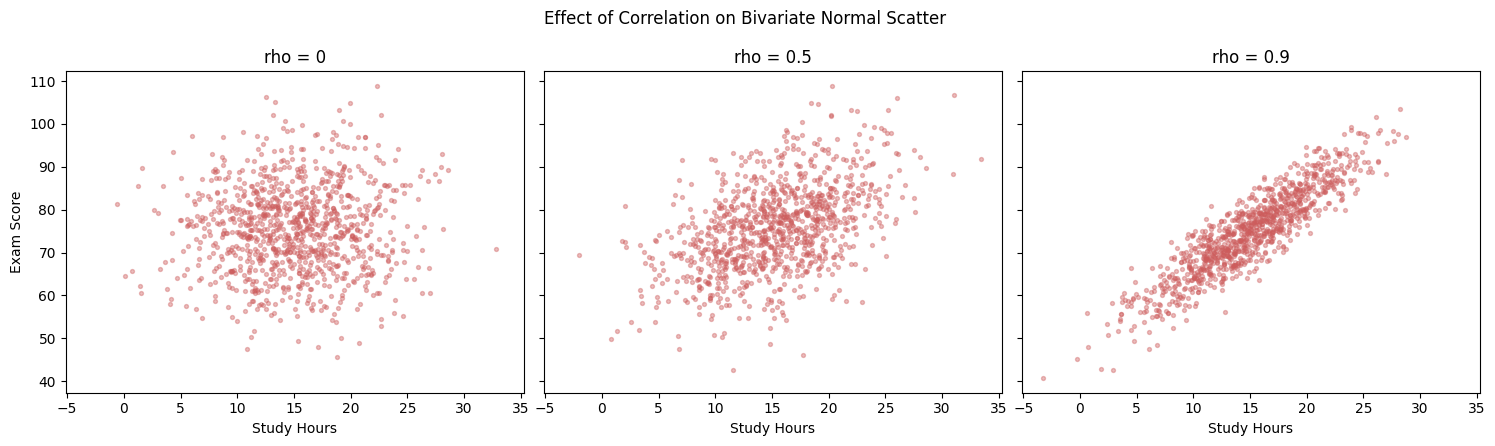

In [ ]:
mu2 = np.array([15, 75])
sd1, sd2 = 5, 10
rhos = [0, 0.50, 0.90]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True, sharey=True)
for ax, rho in zip(axes, rhos):
    cov12 = rho * sd1 * sd2
    Sigma2 = np.array([[sd1**2, cov12],
                        [cov12, sd2**2]])
    Y = np.random.multivariate_normal(mu2, Sigma2, size=1000)
    ax.scatter(Y[:, 0], Y[:, 1], s=8, alpha=0.4, color="indianred")
    ax.set_title(f"rho = {rho}")
    ax.set_xlabel("Study Hours")
axes[0].set_ylabel("Exam Score")
plt.suptitle("Effect of Correlation on Bivariate Normal Scatter")
plt.tight_layout()
plt.show()

In Part C, we investigated how different correlation values affect the relationship between Study Hours and Exam Score. We used three correlation values: 0, 0.50, and 0.90, while keeping the means and standard deviations constant.

When the correlation is 0, there is no clear linear relationship between the two variables, so the points are more widely scattered. At a correlation of 0.50, a moderate positive relationship becomes visible, with the points showing an upward trend. When the correlation increases to 0.90, the positive relationship becomes much stronger, and the observations are more concentrated along an upward-sloping line.

This simulation shows that as the correlation increases, the relationship between the two variables becomes stronger and the observations become more concentrated around a particular direction.

## Part D. Investigate a Linear Combination

Theoretical Mean: 113.50 | Simulated Mean: 113.38
Theoretical Variance: 320.26 | Simulated Variance: 288.40


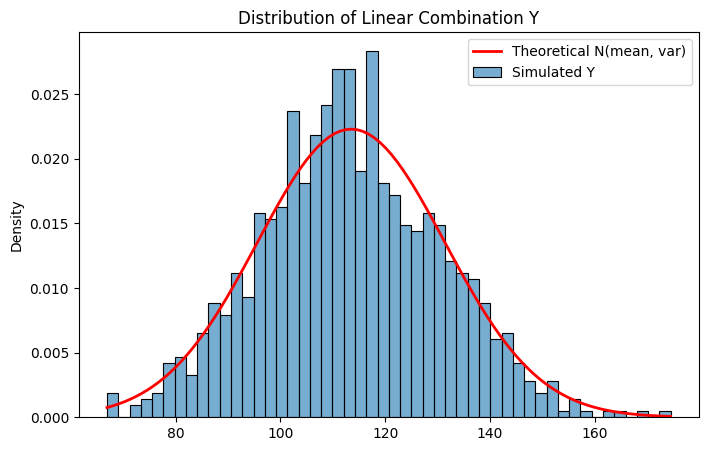

In [8]:
import numpy as np
import pandas as pd # Needed for DataFrame
import matplotlib.pyplot as plt # Needed for plotting
import seaborn as sns # Needed for plotting
from scipy import stats # Needed for stats.norm.pdf

# Re-define mu, Sigma, labels, and df for this cell to make it self-contained
np.random.seed(123) # Re-seed for reproducibility if this cell is run independently

# Mean vector: [Studyhours, Sleephours, Examscore]
mu = np.array([15, 7, 75])

# Covariance matrix
Sigma = np.array([
    [25.00, -1.80, 27.50],
    [-1.80,  1.44,  4.20],
    [27.50,  4.20, 100.00]
])

labels = ["Studyhours", "Sleephours", "Examscore"]

n = 1000
X = np.random.multivariate_normal(mu, Sigma, size=n)
df = pd.DataFrame(X, columns=labels)


a = np.array([1, -2, 1.5])

# theoretical values
theo_mean_Y = np.dot(a, mu)
theo_var_Y = np.dot(a.T, np.dot(Sigma, a))

# simulated values
# Correcting the column names to match the actual DataFrame df
simulated_Y = a[0]*df['Studyhours'] + a[1]*df['Sleephours'] + a[2]*df['Examscore']
sim_mean_Y = simulated_Y.mean()
sim_var_Y = simulated_Y.var()

print(f"Theoretical Mean: {theo_mean_Y:.2f} | Simulated Mean: {sim_mean_Y:.2f}")
print(f"Theoretical Variance: {theo_var_Y:.2f} | Simulated Variance: {sim_var_Y:.2f}")

# plot
plt.figure(figsize=(8, 5))
sns.histplot(simulated_Y, stat='density', bins=50, alpha=0.6, label='Simulated Y')
x_axis = np.linspace(simulated_Y.min(), simulated_Y.max(), 100)
plt.plot(x_axis, stats.norm.pdf(x_axis, theo_mean_Y, np.sqrt(theo_var_Y)),
         color='red', lw=2, label='Theoretical N(mean, var)')
plt.title('Distribution of Linear Combination Y')
plt.legend()
plt.show()

The simulation strongly supports the theoretical property $a'X \sim N(a'\mu, a'\Sigma a)$. The simulated mean and variance match the theoretical values, and the histogram perfectly aligns with the overlaid theoretical normal density curve.

## Part E. Mahalanobis Distance and Chi-Square

Theoretical 90% Threshold (Chi-Sq): 6.25
Proportion of simulated data inside 90% region: 0.9190


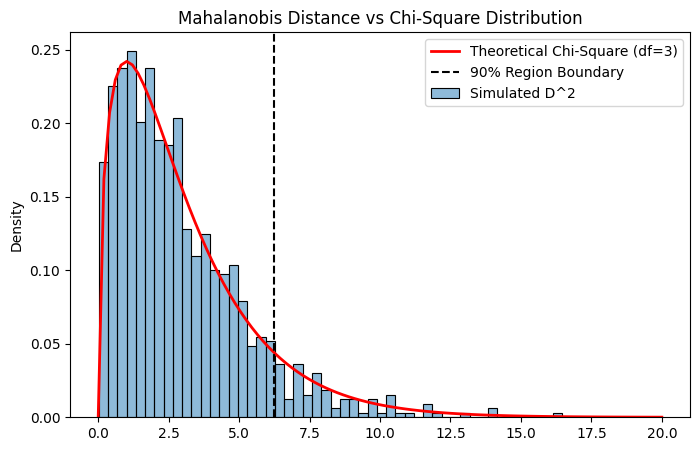

In [5]:
inv_Sigma = np.linalg.inv(Sigma)

diff = X - mu
D2 = np.sum(np.dot(diff, inv_Sigma) * diff, axis=1)

# theoretical comparison
df_chi = 3  # degrees of freedom
threshold_90 = stats.chi2.ppf(0.90, df_chi)
prop_inside_90 = np.mean(D2 <= threshold_90)

print(f"Theoretical 90% Threshold (Chi-Sq): {threshold_90:.2f}")
print(f"Proportion of simulated data inside 90% region: {prop_inside_90:.4f}")

# plot
plt.figure(figsize=(8, 5))
sns.histplot(D2, stat='density', bins=50, alpha=0.5, label='Simulated D^2')
x_axis = np.linspace(0, 20, 100)
plt.plot(x_axis, stats.chi2.pdf(x_axis, df_chi), color='red', lw=2, label='Theoretical Chi-Square (df=3)')
plt.axvline(threshold_90, color='black', linestyle='--', label='90% Region Boundary')
plt.title('Mahalanobis Distance vs Chi-Square Distribution')
plt.legend()
plt.show()

The Mahalanobis distance represents the statistical distance of an observation from the multivariate mean, factoring in the covariance (scaling and correlation). The histogram of $D^2$ perfectly matches the theoretical $\chi^2_3$ curve. Furthermore, approximately 90% of our simulated data falls below the 90th percentile threshold of the $\chi^2_3$ distribution, validating the theorem.  

## Option A - Custom Investigation

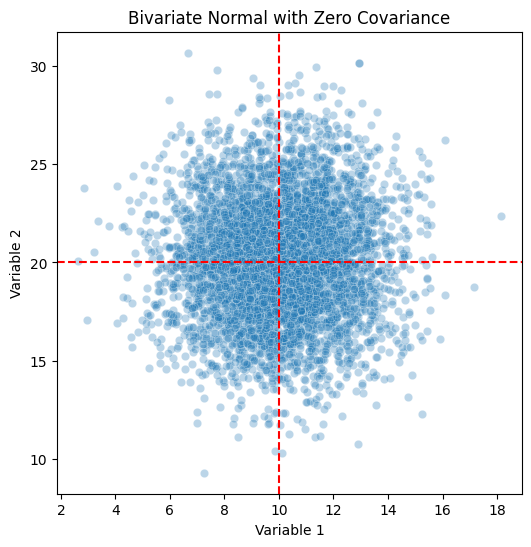

Simulated Correlation between independent variables: 0.0185


In [9]:
mu_ind = [10, 20]
Sigma_ind = [[4, 0],   # Var(X1)=4
             [0, 9]]   # Var(X2)=9, Cov(X1,X2)=0

data_ind = np.random.multivariate_normal(mu_ind, Sigma_ind, 5000)

plt.figure(figsize=(6, 6))
sns.scatterplot(x=data_ind[:, 0], y=data_ind[:, 1], alpha=0.3)
plt.title('Bivariate Normal with Zero Covariance')
plt.xlabel('Variable 1')
plt.ylabel('Variable 2')
plt.axvline(10, color='red', linestyle='--')
plt.axhline(20, color='red', linestyle='--')
plt.show()

sim_corr = np.corrcoef(data_ind[:, 0], data_ind[:, 1])[0, 1]
print(f"Simulated Correlation between independent variables: {sim_corr:.4f}")

The scatterplot shows a perfectly horizontal/vertical elliptical cloud with no tilt. The simulated correlation is extremely close to 0.000. Because knowing the value of Variable 1 provides no information about the spread or mean of Variable 2, the simulation confirms the theoretical result: for multivariate normal vectors, $\sigma_{ij} = 0$ equates to statistical independence.